 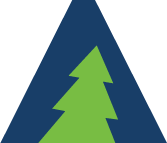 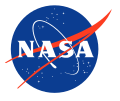 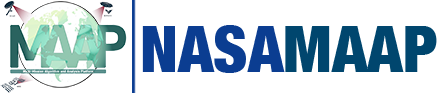   
| 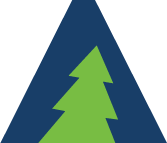 | These products were developed with funding from the [NASA Arctic Boreal Vulnerability Experiment (ABoVE)](https://above.nasa.gov/). |
| ----------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| 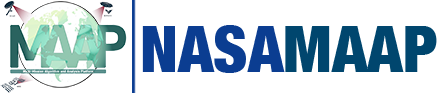 | Code development and data processing are performed on the [NASA Multi-Mission Algorithm and Analysis Platform](https://maap-project.org) |  

# Circumpolar boreal forest structure maps from the `NASA ABoVE Boreal Biomass Mapping` project
### Review details: 
+ HLS trends 


| Contributors | Role | Affiliation | 
| ---------------- | ---------------- | ---------------- |
| Paul Montesano paul.m.montesano@nasa.gov |  Co-I | NASA Goddard Space Flight Center |


#### Documentation 

In [1]:
# import os
# os.environ["PROJ_DATA"] = "/opt/conda/envs/titiler/share/proj"
# os.environ["PROJ_LIB"] = "/opt/conda/envs/titiler/share/proj"
# !pip install cogeo_mosaic

In [2]:
!pip install cogeo_mosaic==8.2.0

In [3]:
# from maap.maap import MAAP
# maap = MAAP()
import geopandas
import pandas as pd
import os
import sys
import importlib

ICESAT2_BOREAL_LIB_PATH = '/projects/my-private-bucket/code/icesat2_boreal/lib'   
sys.path.append(ICESAT2_BOREAL_LIB_PATH)
import maplib_folium
import mosaiclib
from mosaiclib import *

# Shared Review map page template (maap_tools/lib)
sys.path.append(os.path.abspath(os.path.join('..', 'lib')))
import review_maps
review_maps.use_mosaic_registry(maplib_folium)   # reuse TiTiler mosaic ids so tile urls stay stable across reruns

# Map
Note: zoom-in to display map tiles

In [4]:
boreal_tiles = geopandas.read_file(boreal_tile_index_path)

In [5]:
import importlib
importlib.reload(mosaiclib)
importlib.reload(maplib_folium)
review_maps.use_mosaic_registry(maplib_folium)   # re-apply after the reload

<module 'maplib_folium' from '/projects/my-private-bucket/code/icesat2_boreal/lib/maplib_folium.py'>

In [6]:
TRENDS_NDVI_HLS = [
    maplib_folium.make_tiles_layer_dict(
        None, 
        mosaiclib.MISC_MOSAIC_JSON_FN_DICT['NDVI_trends_HLS'], 
        "NDVI Trends across HLS", 
        SHOW_CBAR=True, 
        PARAMS_DICT = {"rescale": f"-0.02,0.02", "bidx":"1", "colormap_name": 'BrBG'}
        ),
    
] 

Registering mosaic with Titiler: s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/TRENDNDVI_SLOPE/main/TRENDNDVI_SLOPE_tindex_master_mosaic.json
{'tilejson': '3.0.0', 'version': '1.0.0', 'scheme': 'xyz', 'tiles': ['https://titiler-pgstac.maap-project.org/mosaics/d441b435-cdc6-4cff-ab2c-6b9502f08be5/tiles/WebMercatorQuad/{z}/{x}/{y}?rescale=-0.02%2C0.02&bidx=1&colormap_name=brbg&tilesize=512'], 'minzoom': 6, 'maxzoom': 18, 'bounds': [-180.0, 51.0, -129.0, 72.0], 'center': [-154.5, 61.5, 6], 'raster_layers': {}}


In [7]:
# Make ESRI gray the only basemap on at opening
for k, bm in maplib_folium.basemaps.items():
    bm.show = (k == 'basemap_gray')
    bm._children.pop(bm.get_name() + '_add', None)   # clear the 'add to map' step left by an earlier display

# NDVI trends only (the other layers are shown in the other Review maps)
MAP_LAYERS = TRENDS_NDVI_HLS
for d in MAP_LAYERS:
    d['layer'].show = True                    # on at opening
    d['layer'].options['minZoom'] = 7         # the tiler times out (503) on lower-zoom tiles of this mosaic

m = maplib_folium.MAP_REGISTERED_DPS_RESULTS(
                                boreal_tiles,
                                None,
                                CHECK_TILES_NAME='',
                                ecoboreal_geojson=None,   # no boreal ecoregion outline
                                map_width=750, map_height=500, SHOW_WIDGETS=False,
                                ADD_TILELAYER = MAP_LAYERS
                             )

# Drop the boreal tile grid that MAP_REGISTERED_DPS_RESULTS always adds
review_maps.drop_layer(m, 'Boreal tiles')

# Open over interior Alaska, where the NDVI trend data are (tiles draw at zoom 7+)
m.location = [64.8, -148.0]
m.options['zoom'] = 7

Adding layer NDVI Trends across HLS...


## Build in raster query

In [8]:
BASE = 'https://titiler-pgstac.maap-project.org/mosaics'
AGB_2025_POINT = f'{BASE}/a9a8784a-f7a3-4db6-be1e-92733fb7f213/point/{{lon}},{{lat}}'
CACC_2020_POINT = f'{BASE}/1a909d38-dfce-4e3d-959f-2717dc772aed/point/{{lon}},{{lat}}'
TREND_20162025_POINT = f'{BASE}/2930623a-621a-4825-b830-91e523e46619/point/{{lon}},{{lat}}'
TRENDS_NDVI_HLS_POINT = f'{BASE}/2fec0901-1754-4a4d-9421-218497e1f7f8/point/{{lon}},{{lat}}'

query_layers = [
    {'section': 'NDVI trend from HLS (Alaska)', 'name': 'slope',
     'point_url': f'{TRENDS_NDVI_HLS_POINT}?bidx=1', 'units': ''},
]

# After m is built with your tile layers:
m = maplib_folium.add_pixel_query(m, query_layers, decimals=4)

In [9]:
print(query_layers[0]['point_url'])

https://titiler-pgstac.maap-project.org/mosaics/2fec0901-1754-4a4d-9421-218497e1f7f8/point/{lon},{lat}?bidx=1


In [10]:
from folium import GeoJson, features

In [11]:
from folium import LayerControl

In [12]:
# out_html is set in the save cell below (repo's maps/ dir)

In [13]:
m

### Save to html

### Page header
Shared Review map template (`maap_tools/lib/review_maps.py`): title + logos, dataset table with a status per row, usage note, references, footer.

In [14]:
from review_maps import COMPLETE, WIP

HLS_NDVI = {
    'title': 'NDVI Trends from Harmonized Landsat Sentinel-2',
    'subtitle': 'NASA HLS Circumpolar NDVI Trends Assessment',
    'logos': ['nasa'],
    'note': 'Tiles display at zoom level 7 and closer (lower zooms exceed the tile server time limit). Coverage is currently Alaska only. '
            'Click anywhere on the map to query the NDVI slope.',
    'refs': [],
    'rows': [
        {'layer': 'NDVI trend from HLS', 'resolution': '30&thinsp;m',
         'description': 'Per-pixel slope of NDVI from Harmonized Landsat Sentinel-2 (HLS), shown from '
                        '&minus;0.02 to +0.02. Alaska only (west of 129&deg;W).',
         'citation': '&mdash;', 'status': WIP},
    ],
}

In [15]:
# Save next to the other published maps (repo's maps/ dir), relative to this notebook
out_html = os.path.abspath(os.path.join('..', 'maps', 'Review_maps_HLS_trends.html'))
header_html = review_maps.build_header_html(HLS_NDVI['title'], HLS_NDVI['subtitle'], HLS_NDVI['rows'], HLS_NDVI['note'],
                                            HLS_NDVI['refs'], logos=HLS_NDVI['logos'])
review_maps.save_review_map(m, out_html, header_html)

Saved /projects/my-private-bucket/code/maap_tools/maps/Review_maps_HLS_trends.html — push to GitHub to view at:
  https://pahbs.github.io/maap_tools/maps/Review_maps_HLS_trends.html
